In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import Ridge, Lasso

# Exercise 4 (4 points)

Predict whether a patient will experience disorientation within 12 hours of receiving a 100 mg dose of a new medication.

Predictors: body fat, meat in diet, stress level, blood oxygen, blood sugar.

In [15]:
training_data = pd.DataFrame({
    'fat':   [15.22442, 28.51168,  6.13891, 18.20264, 16.41537, 19.31584,  7.57312, 27.49562,  6.05149, 13.19802, 28.86259, 21.01267, 21.39264, 19.85355, 12.22899, 29.07561, 27.55748, 24.88669, 16.94490, 23.96149, 12.95453, 10.79064, 15.34311,  8.81112,  8.47015, 10.82585, 16.64906,  6.14578, 10.16328,  7.37102, 15.99579, 23.86188,  5.01562, 10.50297, 14.49541, 13.79495,  7.77839, 11.09049,  7.57162,  9.37632,  8.26739, 13.00933,  7.33987, 16.66948, 19.99972, 17.21533, 28.86185, 17.07256,  8.67737, 28.38250,  8.55736, 18.73212, 12.69300, 14.23722,  8.85506,  7.27610, 20.48141, 21.82498, 23.42694, 24.65704, 15.23687, 26.06823, 11.14309, 11.16122,  7.77741, 14.74986, 21.24963, 18.34220, 10.52757, 15.31865, 11.64217, 23.66420, 21.70712, 12.81120, 22.70726, 17.03225, 11.62582, 27.54686, 13.03707, 29.64102,  8.80867, 19.32168, 10.96815, 20.03414, 12.20598,  9.26613,  9.30429, 17.05107, 22.52133, 23.20986, 27.89209, 15.71054,  6.46196, 20.82638, 24.63229, 15.10998, 16.78941, 28.14270, 17.57033,  5.15752,  9.10528, 21.22045, 23.96483,  6.62321,  6.36573, 12.44354, 27.01101, 25.41515, 29.55351,  7.58999, 24.97079, 24.61438,  5.23575, 23.23477, 20.75330,  5.20539, 17.30733],
    'meat':  [121.7750, 141.3636,  94.5035, 184.0134, 135.3303, 148.9152, 233.9748,  92.9359, 242.5512,  65.6625, 253.7704, 128.0282, 179.7012,  56.3817, 297.2696, 284.7846, 221.9019, 254.1195, 234.7579, 137.1799, 183.8853, 118.6363, 258.0269, 238.2775, 291.0381,  70.3666, 263.5912, 131.8993, 196.7397, 282.3377, 271.2832, 188.3285, 155.8659, 227.2595, 153.3264, 191.6835, 172.5159, 269.6685, 268.4875, 195.6849, 181.6475,  72.0908, 134.3738, 273.5837, 109.3074, 106.4546, 129.6236,  93.4960, 143.5423, 207.4364, 245.4558, 272.9740, 243.8519,  60.5270, 118.4378, 262.6169, 239.7838, 164.4804, 232.4079, 238.0094, 249.7059,  72.5805, 125.1294, 191.7799, 234.1551, 264.3619,  79.3328,  68.7392,  89.2920, 211.7643,  93.3794, 120.7506, 155.1087, 228.6887, 257.8055, 187.6542, 180.5839, 113.4552, 208.7001, 184.8902, 157.1533, 138.9404, 261.2334,  55.7861, 144.1111,  96.4683, 157.2351, 207.6934, 146.1142, 235.6348,  55.7137, 268.7206, 281.1197, 199.3384, 172.4593, 272.0929,  59.1761, 178.4453, 213.3570, 253.2783, 251.8748, 252.1530, 114.7003, 100.8543, 120.7832, 283.4241, 172.3570, 151.9077,  75.9279, 120.1413, 114.8112, 167.6705, 141.4614,  61.7484, 115.6991, 169.4555, 216.9101],
    'stress':[16.01848, 84.77392, 47.78868, 77.36921, 44.05331, 50.69977,  1.91910, 77.36860, 64.14626, 46.84321, 27.92238, 58.55656, 81.12373, 45.54890, 26.88034, 23.12309, 54.32329, 13.02881, 54.79943, 14.92442, 42.68856, 44.77301, 45.68868, 24.24571,  7.58608, 39.12951,  1.31082, 70.88554, 27.64399, 17.30430, 56.19632, 78.84094, 80.04764, 62.89278, 27.14090, 41.98642, 35.54347, 39.23313, 75.93357, 48.01264, 80.62479, 73.87485, 62.45530, 28.86901, 80.09179, 21.70480, 74.42385, 86.66537, 66.05323,  7.22866, 24.43082, 42.18101, 71.86118, 13.83901, 93.10996, 56.83380, 54.02562, 70.29795, 56.77484, 28.80103, 40.53639, 21.71838, 32.82387, 91.89548, 52.87654, 37.19788, 45.92408,  7.24691, 28.69576, 14.94125, 97.24320, 91.63057, 21.66621, 21.05232, 67.90228, 13.49964, 38.74983, 59.42730, 55.50781, 44.94114, 96.85509, 38.51986, 85.85914, 48.90915, 15.76628, 78.53486, 54.21883, 41.65473, 81.36684, 11.16880, 53.09357, 27.75601, 58.87063, 44.02418, 86.59671, 24.45707, 98.15432, 24.87264, 97.28035, 72.52280, 56.61824, 39.21965, 20.20875, 73.55584, 34.61270, 81.57680, 84.81077, 30.33252, 77.05970, 73.34485, 56.90488,  2.62808, 48.61272, 83.66601, 72.86645, 13.65023,  9.96219],
    'oxygen':[83.6896, 90.8647, 86.6990, 87.5413, 87.9056, 76.6831, 82.6051, 82.5995, 81.4134, 82.6705, 75.7428, 91.9361, 91.9372, 82.5524, 89.3152, 95.0033, 90.8430, 82.4272, 77.5004, 81.2130, 97.9481, 84.2903, 79.9335, 90.2899, 78.3200, 71.5857, 82.7728, 99.0940, 79.5550, 79.3722, 95.9518, 78.2977, 80.7598, 92.3828, 70.8888, 77.6988, 84.9405, 89.6007, 94.3718, 80.4590, 93.8067, 79.8347, 75.3501, 92.2405, 89.1756, 77.6580, 94.6172, 94.1134, 84.0870, 86.7187, 81.7985, 88.2654, 71.7628, 84.0713, 87.4516, 75.6066, 93.8296, 82.6908, 89.6314, 77.7251, 94.8722, 84.0087, 81.8339, 81.4814, 70.9591, 85.6434, 78.2543, 82.0019, 81.7155, 82.7188, 78.5927, 92.3585, 76.1946, 86.1706, 99.8912, 71.0597, 85.7684, 98.5851, 72.4986, 77.7978, 84.6447, 75.6327, 91.3910, 83.8360, 87.8448, 99.6956, 88.4623, 78.1923, 98.3687, 86.6992, 75.9144, 83.4023, 98.1105, 70.1609, 84.9976, 82.0313, 83.4262, 90.5000, 97.2617, 89.1730, 88.0338, 84.1598, 74.8289, 98.9880, 90.3236, 77.2495, 95.0857, 79.9657, 89.3421, 98.7585, 85.3084, 74.6579, 95.3755, 90.0962, 88.5327, 87.4766, 85.5540],
    'sugar': [ 86.4098, 124.2110, 137.7977, 119.2165,  94.4018, 136.9460, 179.1374,  91.0309,  96.6626, 106.0197,  70.3889, 179.7458,  82.2624, 133.4980, 115.7982, 133.1609, 133.5399,  94.5221, 151.0157, 137.3644, 175.5863, 151.9320, 117.8817, 171.0932, 169.7367, 159.7064,  91.9728, 134.9433,  84.0553, 163.6432, 172.7028,  84.0571, 114.0314, 154.4359, 127.4085, 176.2366,  75.3884,  86.8639, 121.1025, 104.6850,  86.9146, 104.1532, 115.7383, 127.4459, 139.2826, 116.7186, 176.0146, 144.9098, 162.1275, 149.2690,  94.1815, 153.9417,  99.6936, 165.4600, 163.5029, 127.6326,  88.1005,  85.1849,  86.4693, 159.2210,  89.8967,  86.7809, 139.7575,  87.7186, 110.5968, 103.2440, 139.3319, 179.6168, 178.9080, 151.9837, 118.0425, 116.9203, 160.2858, 142.7013,  70.9589,  73.1000, 163.0031, 152.0505,  88.9258, 143.6688, 114.3601,  84.1183, 160.2181, 156.7157, 147.8048, 132.0036, 101.1089, 113.1262,  81.3519, 161.3834,  90.2796, 164.4737, 141.3023, 176.6171,  95.9863, 107.4494,  76.4230, 145.6844,  98.4506, 104.3051,  73.3602,  75.5183, 109.5803, 129.2459, 137.5516,  95.0392, 116.3993,  96.2021, 102.0794, 166.4035, 164.3029, 122.5013, 168.3654, 138.3177, 149.5037, 143.8684, 105.8116],
    'disorientation': [0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0]
})

val_data = pd.DataFrame({
    'fat':   [ 6.38255, 10.94374, 13.84965, 26.42214, 26.34408, 12.39739, 22.59980, 27.87659, 12.15713, 23.44494, 17.31416, 15.36838,  7.98512, 18.15074, 29.58375, 17.87680,  9.07676, 29.64885, 25.88138,  8.59543, 27.41847, 14.08251, 24.59866,  5.44415, 15.54612, 29.09608, 24.36479, 24.22985, 12.05546, 10.26218, 29.42748, 12.40755, 23.14958,  7.94785, 29.78091, 29.65136, 27.63274, 14.88622, 16.24506],
    'meat':  [271.0334,  81.5207, 197.4754, 190.4189, 222.1803, 127.8177, 297.7586, 233.4880, 242.9774, 165.7438, 193.0184, 290.6053, 234.0835, 203.1809, 274.5902, 297.9363, 228.7834, 159.0119, 272.2554, 156.1130, 211.8605, 204.4815, 117.7039,  78.5636,  85.1615, 218.3887,  53.2603,  87.1484, 124.4308, 105.7203, 191.4136, 239.1625, 217.4009,  62.7200, 249.4757, 280.9248, 263.0911, 217.0809, 177.8286],
    'stress':[23.68726, 25.51057, 54.80433,  3.39015, 80.61095, 33.77528, 35.71064, 64.14732, 32.03521, 58.14332, 17.03690, 30.22353, 45.65182, 38.43425, 29.10830, 13.13782,  2.48171, 47.55582, 48.88076, 64.88825, 83.69779, 23.34955, 29.88560, 58.55671, 33.92215, 82.35256, 37.39821,  7.58029, 86.95323, 23.48996, 99.30155, 67.81977, 43.54868,  5.32594, 23.71979, 23.32397,  6.17263, 24.41251, 75.81855],
    'oxygen':[90.6786, 83.4781, 88.0812, 70.1383, 99.8498, 82.1939, 96.0862, 93.0943, 85.0223, 97.7759, 79.4738, 80.1829, 84.4494, 82.4798, 89.2735, 83.8589, 72.1404, 87.3874, 98.1567, 87.2457, 72.6928, 85.0342, 76.6977, 96.5892, 78.4751, 98.0727, 82.4523, 77.3652, 81.7555, 88.0632, 86.2382, 99.7247, 77.6137, 73.3715, 86.0733, 83.3149, 74.7207, 86.8613, 86.5207],
    'sugar': [140.1384, 142.9693,  92.1768, 134.5545, 146.4577, 128.1117, 146.8320, 130.9489,  93.2212, 140.0033,  78.0529, 141.4933,  87.1985, 170.1158, 132.2852, 101.0591, 150.2976,  77.2895, 116.4625, 130.4727,  96.3994, 123.0886,  98.9132, 143.0732, 166.6565,  97.2321, 171.7536, 111.5294, 157.3796, 148.1768, 132.2279,  71.1127,  98.2646, 140.9932, 169.1219, 150.5554,  94.6809, 158.3037, 104.3649],
    'disorientation': [1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1]
})

print(training_data.head())

        fat      meat    stress   oxygen     sugar  disorientation
0  15.22442  121.7750  16.01848  83.6896   86.4098               0
1  28.51168  141.3636  84.77392  90.8647  124.2110               1
2   6.13891   94.5035  47.78868  86.6990  137.7977               0
3  18.20264  184.0134  77.36921  87.5413  119.2165               0
4  16.41537  135.3303  44.05331  87.9056   94.4018               0


Using all the concepts and models covered so far, build the best solution you can.

**Note:** you are evaluated on your **process** (including hyperparameter search), not just the final model.

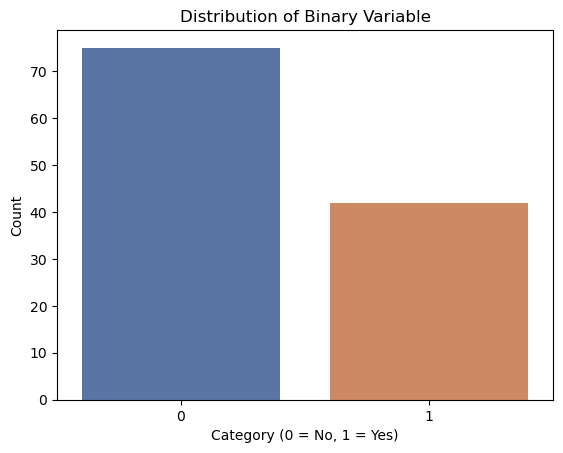

In [ ]:
#  EDA
#  This is a problem of supervised binary classification
#  Let's take a look at the variables we are going to be working with

temp = training_data.copy()

y_train4 = temp['disorientation']  #  variable objetivo

sns.countplot(x='disorientation', data=temp, hue= 'disorientation', legend=False, palette='deep')

plt.title('Distribution of Binary Variable')
plt.xlabel('Category (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

*The target variable is moderately imbalanced, with more cases of class 0 than class 1, although both classes are sufficiently represented.*

*Given that the distribution of the target variable is not balanced, accuracy may give a misleading impression of performance, since it can favour the majority class (**No disorientation**). The statement does not explicitly specify whether false negatives or false positives are more critical. However, since this is a medical context, it is generally more appropriate to place special attention on false negatives, as failing to detect a patient at risk could be potentially risky. For this reason, we will rely on the F1-score as the main evaluation metric, since it provides a better balance between precision and recall than accuracy alone.*

In [134]:
training_data.describe()

,fat,meat,stress,oxygen,sugar,disorientation
count,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000
mean,16.254162,176.681474,49.213944,85.179309,125.053504,0.358974
std,7.165509,68.762121,26.062191,7.481186,31.881868,0.481763
min,5.015620,55.713700,1.310820,70.160900,70.388900,0.000000
25%,10.163280,120.750600,27.643990,79.834700,95.986300,0.000000
50%,15.710540,178.445300,47.788680,84.290300,124.211000,0.000000
75%,21.824980,238.277500,72.866450,90.323600,151.983700,1.000000
max,29.641020,297.269600,98.154320,99.891200,179.745800,1.000000


*The predictors show different numerical scales, so feature standardization may be important for models sensitive to scale (logistic regression, SVM, k-NN, and neural networks).*

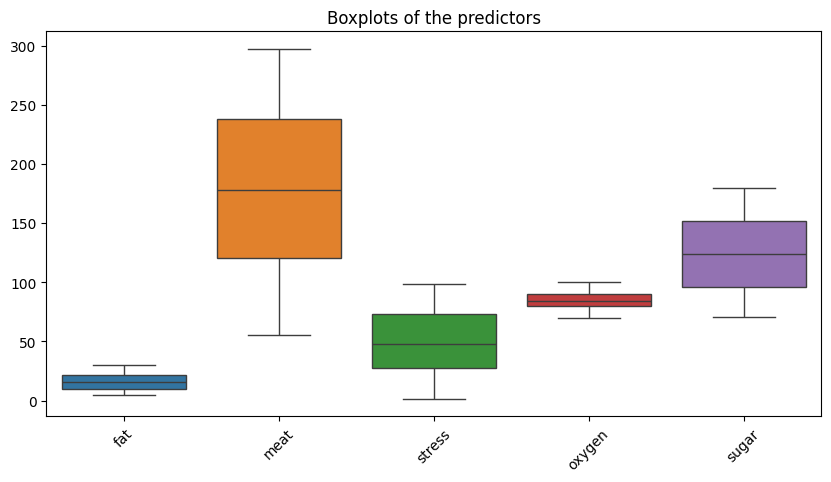

In [135]:
#  Boxplots
plt.figure(figsize=(10, 5))
sns.boxplot(data=training_data.drop(columns="disorientation"))
plt.title("Boxplots of the predictors")
plt.xticks(rotation=45)
plt.show()

*These boxplots show that the predictors are measured on clearly different numerical scales. This supports the use of a standardization forward. In addition, the boxplots allow us to inspect dispersion and possible outliers.*

*It seems also that the variables might be symmetrically distributed.*

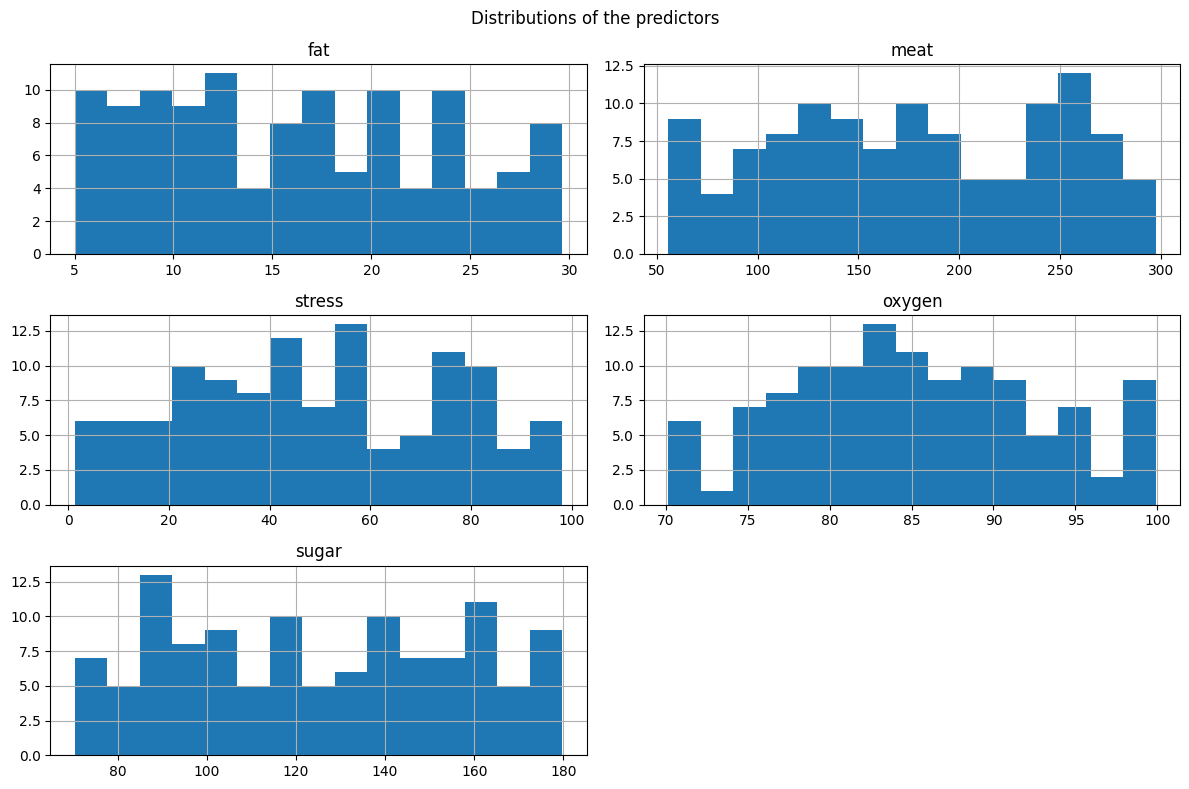

In [136]:
#  Distributions
training_data.drop(columns="disorientation").hist(figsize=(12, 8), bins=15)
plt.suptitle("Distributions of the predictors")
plt.tight_layout()
plt.show()

*The histograms suggest that the predictors do not show strong skewness or extreme concentration in a narrow range, although none of them appears perfectly Gaussian. Most variables are fairly spread across their respective ranges, and no severe distributional anomalies are evident from these plots alone*

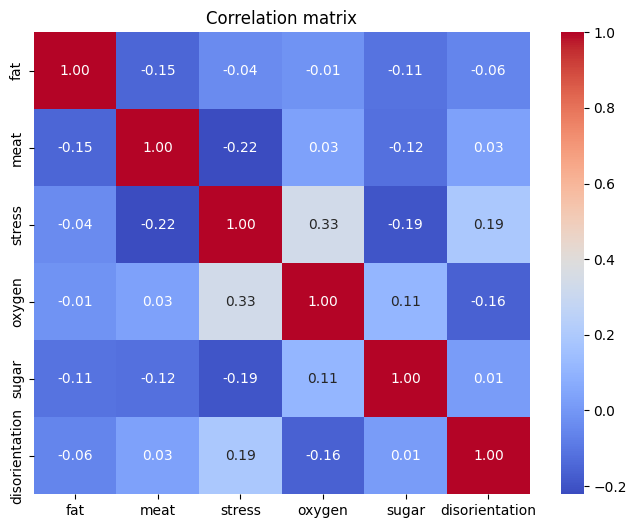

In [137]:
#  Correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(training_data.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation matrix")
plt.show()

*The correlation matrix does not show strong linear relationships among the predictors, so there is no clear evidence of severe multicollinearity. In addition, none of the predictors appears to have an unusually strong linear correlation with the target.*

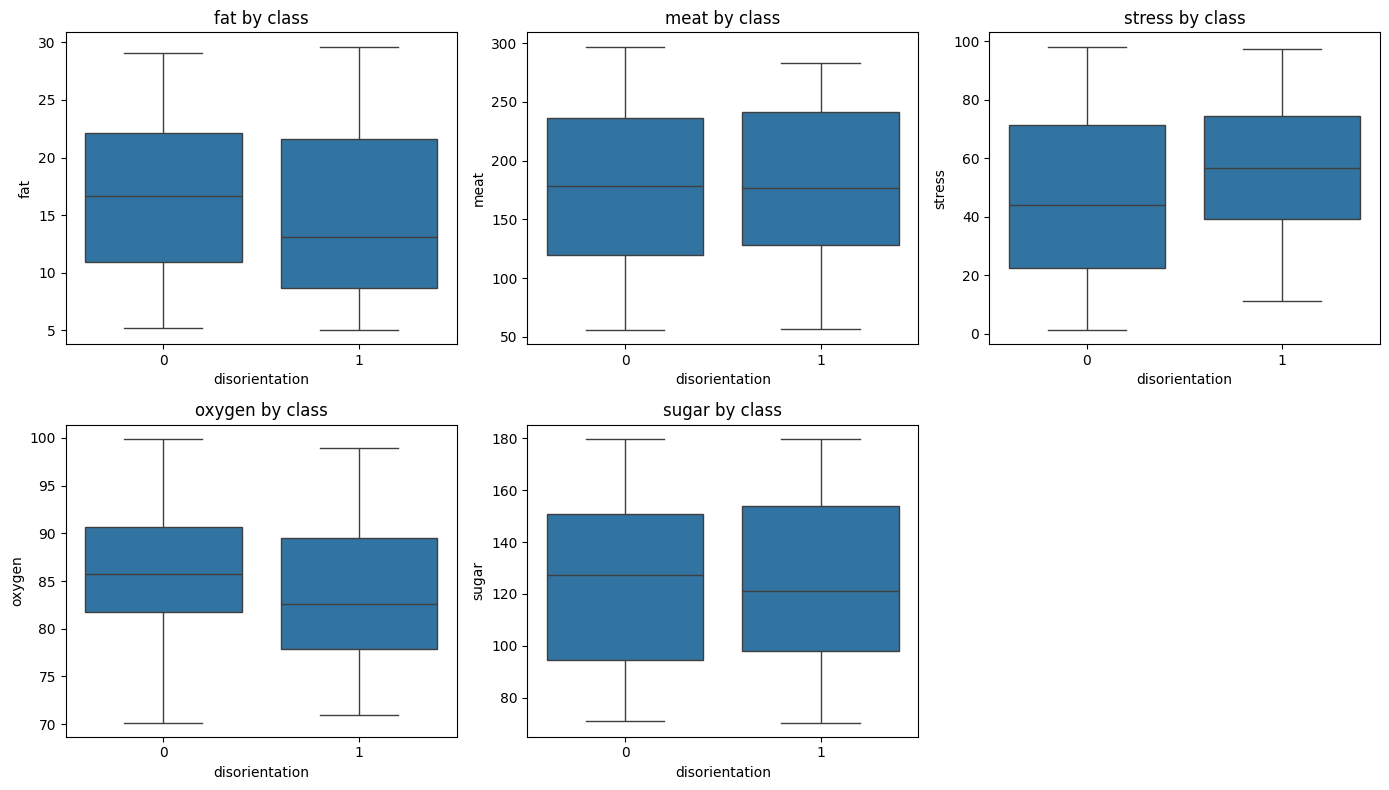

In [138]:
#  Boxplots by class
features = training_data.drop(columns="disorientation").columns

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(data=training_data, x="disorientation", y=col, ax=axes[i])
    axes[i].set_title(f"{col} by class")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

*These boxplots do not show strong separation between the two classes for most predictors, since the distributions overlap substantially. This suggests that no single variable is able to discriminate the target on its own in a very clear way.*

*However, some variables show slight differences between classes. In particular, **stress** tends to be somewhat higher for patients with disorientation, while **oxygen** appears slightly lower. The remaining variables show only modest differences in their central tendency and spread.*

*Overall, these plots suggest that the classification problem may require combining several predictors rather than relying on one strongly discriminative feature.*

In [139]:
training_data.isna().sum()

fat               0
meat              0
stress            0
oxygen            0
sugar             0
disorientation    0
dtype: int64

*Given that no obvious outliers or missing values were detected in the exploratory analysis, we conclude the EDA at this point.*

*The main issue to keep in mind for the modelling stage is that the predictors are measured on different numerical scales, so standardization will be necessary for models that are sensitive to feature magnitude.*

In [17]:
#  Data prep
X_train = training_data.drop('disorientation', axis=1)
X_val = val_data.drop('disorientation', axis=1)

y_train = training_data['disorientation']
y_val = val_data['disorientation']

### Logistic Regression

c:\Users\usuar\anaconda3\envs\xndl\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\usuar\anaconda3\envs\xndl\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\usuar\anaconda3\envs\xndl\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid 

Best Hyperparameters: {'model__C': 1.0, 'model__class_weight': 'balanced', 'model__penalty': 'l2', 'model__solver': 'lbfgs', 'scaler': StandardScaler()}
Training accuracy: 0.6666666666666666
Validation accuracy: 0.6153846153846154
Training F1: 0.5806451612903226
Validation F1: 0.4

Validation classification report:

              precision    recall  f1-score   support

           0       0.66      0.79      0.72        24
           1       0.50      0.33      0.40        15

    accuracy                           0.62        39
   macro avg       0.58      0.56      0.56        39
weighted avg       0.60      0.62      0.60        39



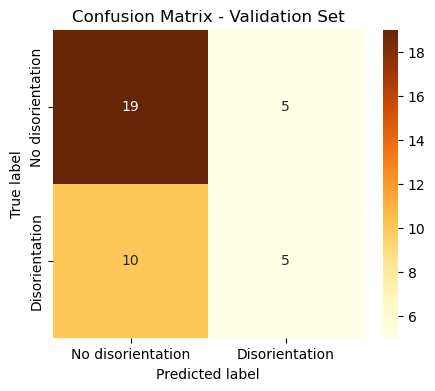

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

#  Pipeline
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=10000))
])

#  Parameter grid
param_grid = [
    {
        'scaler': [StandardScaler(), MinMaxScaler(), 'passthrough'],
        'model__C': [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0, 20.0, 50.0, 100.0],
        'model__penalty': ['l2'],
        'model__solver': ['lbfgs'],
        'model__class_weight': [None, 'balanced']
    }
]

#  We use F1-score as the evaluationmetric 
grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=3,
    scoring='f1'
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

train_preds = best_model.predict(X_train)
val_preds = best_model.predict(X_val)

print("Best Hyperparameters:", grid_search.best_params_)
print("Training accuracy:", accuracy_score(y_train, train_preds))
print("Validation accuracy:", accuracy_score(y_val, val_preds))
print("Training F1:", f1_score(y_train, train_preds))
print("Validation F1:", f1_score(y_val, val_preds))

print("\nValidation classification report:\n")
print(classification_report(y_val, val_preds))

cm = confusion_matrix(y_val, val_preds)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='YlOrBr',
    xticklabels=['No disorientation', 'Disorientation'],
    yticklabels=['No disorientation', 'Disorientation']
)
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix - Validation Set')
plt.show()

*Although the number of false positives increases when optimizing for F1-score, the model now detects more true disorientation cases and reduces the number of false negatives. Since, in a medical setting, failing to identify a patient at risk is usually more problematic than issuing some extra false alarms, this trade-off is preferable.*

*However, logistic regression does not appear to be the most suitable model for this particular binary classification problem, as its overall performance remains limited even after adjusting the evaluation criterion and accounting for class imbalance.*

### SVM

Best Hyperparameters: {'model__C': 50.0, 'model__class_weight': 'balanced', 'model__gamma': 'auto', 'model__kernel': 'rbf', 'scaler': MinMaxScaler()}
Training accuracy: 0.717948717948718
Validation accuracy: 0.6410256410256411
Training F1: 0.6451612903225806
Validation F1: 0.5333333333333333

Validation classification report:

              precision    recall  f1-score   support

           0       0.71      0.71      0.71        24
           1       0.53      0.53      0.53        15

    accuracy                           0.64        39
   macro avg       0.62      0.62      0.62        39
weighted avg       0.64      0.64      0.64        39



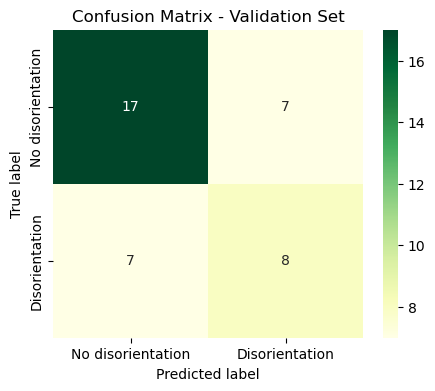

In [20]:
from sklearn.svm import SVC

#  Pipeline
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVC())
])

#  Parameter grid
param_grid = [
    {
        'scaler': [StandardScaler(), MinMaxScaler(), 'passthrough'],
        'model__C': [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0, 20.0, 50.0, 100.0],
        'model__kernel': ['linear', 'rbf'],
        'model__gamma': ['scale', 'auto'],
        'model__class_weight': [None, 'balanced']
    }
]

#  We use F1-score as the evaluation metric
grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=3,
    scoring='f1'
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

train_preds = best_model.predict(X_train)
val_preds = best_model.predict(X_val)

print("Best Hyperparameters:", grid_search.best_params_)
print("Training accuracy:", accuracy_score(y_train, train_preds))
print("Validation accuracy:", accuracy_score(y_val, val_preds))
print("Training F1:", f1_score(y_train, train_preds))
print("Validation F1:", f1_score(y_val, val_preds))

print("\nValidation classification report:\n")
print(classification_report(y_val, val_preds))

cm = confusion_matrix(y_val, val_preds)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='YlGn',
    xticklabels=['No disorientation', 'Disorientation'],
    yticklabels=['No disorientation', 'Disorientation']
)
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix - Validation Set')
plt.show()

*The SVM model provides a substantially better balance between the two classes than logistic regression. According to the confusion matrix, it correctly identifies 8 positive cases of disorientation while reducing the number of false negatives to 7. Although the number of false positives also increases compared with the logistic regression model, the trade-off is preferable in this medical setting, where missing a patient at risk is generally more serious than issuing an additional false alarm.*

*Overall, the SVM achieves a more balanced classification behaviour and shows a better ability to detect the positive class. This suggests that the relationship between the predictors and the target is not captured well enough by a purely linear probabilistic model such as logistic regression, whereas SVM is able to find a more suitable separating boundary for this dataset.*

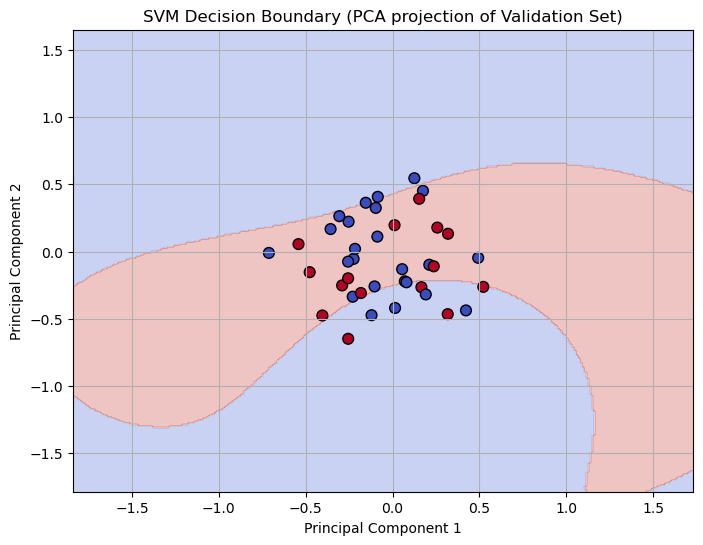

In [21]:
#  Aproximación visual del SVM
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

#  Escalamos los datos con el scaler del mejor pipeline
best_scaler = best_model.named_steps['scaler']
X_train_scaled = best_scaler.transform(X_train) if best_scaler != 'passthrough' else X_train
X_val_scaled = best_scaler.transform(X_val) if best_scaler != 'passthrough' else X_val

#  Reducimos a 2 dimensiones con PCA
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_val_pca = pca.transform(X_val_scaled)

#  Entrenamos un SVM en 2D solo para visualizar
best_svm = best_model.named_steps['model']
svm_vis = best_svm.__class__(
    C=best_svm.C,
    kernel=best_svm.kernel,
    gamma=getattr(best_svm, "gamma", 'scale'),
    class_weight=best_svm.class_weight
)
svm_vis.fit(X_train_pca, y_train)

#  Crear malla
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

Z = svm_vis.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

#  Dibujar frontera
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')

#  Dibujar puntos reales
scatter = plt.scatter(
    X_val_pca[:, 0],
    X_val_pca[:, 1],
    c=y_val,
    cmap='coolwarm',
    edgecolor='k',
    s=60
)

plt.title('SVM Decision Boundary (PCA projection of Validation Set)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True)
plt.show()

### Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

#  Model
model = RandomForestClassifier(random_state=42)

#  Parameter grid
param_grid = {
    'n_estimators': [50, 100, 200, 300],
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2'],
    'class_weight': [None, 'balanced']
}

#  We use F1-score as the evaluation metric
grid_search = GridSearchCV(
    model,
    param_grid,
    cv=3,
    scoring='f1'
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

train_preds = best_model.predict(X_train)
val_preds = best_model.predict(X_val)

print("Best Hyperparameters:", grid_search.best_params_)
print("Training accuracy:", accuracy_score(y_train, train_preds))
print("Validation accuracy:", accuracy_score(y_val, val_preds))
print("Training F1:", f1_score(y_train, train_preds))
print("Validation F1:", f1_score(y_val, val_preds))

print("\nValidation classification report:\n")
print(classification_report(y_val, val_preds))

cm = confusion_matrix(y_val, val_preds)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='GnBu',
    xticklabels=['No disorientation', 'Disorientation'],
    yticklabels=['No disorientation', 'Disorientation']
)
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix - Validation Set')
plt.show()

*The Random Forest model does not perform as well as the SVM on this problem. Although it correctly classifies a large number of negative cases, it still misses many true disorientation cases, leading to a high number of false negatives. In a medical setting, this is a relevant limitation, since failing to identify patients at risk is usually more serious than producing some additional false positives. Therefore, despite being a flexible non-linear model, Random Forest does not appear to be the most suitable option for this dataset.*

### KNN

Best Hyperparameters: {'model__metric': 'manhattan', 'model__n_neighbors': 3, 'model__p': 1, 'model__weights': 'uniform', 'scaler': MinMaxScaler()}
Training accuracy: 0.8205128205128205
Validation accuracy: 0.5897435897435898
Training F1: 0.72
Validation F1: 0.2727272727272727

Validation classification report:

              precision    recall  f1-score   support

           0       0.62      0.83      0.71        24
           1       0.43      0.20      0.27        15

    accuracy                           0.59        39
   macro avg       0.53      0.52      0.49        39
weighted avg       0.55      0.59      0.54        39



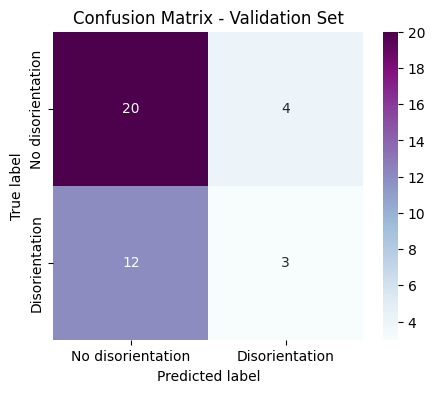

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Pipeline
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier())
])

# Parameter grid
param_grid = [
    {
        'scaler': [StandardScaler(), MinMaxScaler(), 'passthrough'],
        'model__n_neighbors': [3, 5, 7, 9, 11, 15],
        'model__weights': ['uniform', 'distance'],
        'model__metric': ['euclidean', 'manhattan', 'minkowski'],
        'model__p': [1, 2]
    }
]

# We use F1-score as the evaluation metric
grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=3,
    scoring='f1',
    verbose = 1
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

train_preds = best_model.predict(X_train)
val_preds = best_model.predict(X_val)

print("Best Hyperparameters:", grid_search.best_params_)
print("Training accuracy:", accuracy_score(y_train, train_preds))
print("Validation accuracy:", accuracy_score(y_val, val_preds))
print("Training F1:", f1_score(y_train, train_preds))
print("Validation F1:", f1_score(y_val, val_preds))

print("\nValidation classification report:\n")
print(classification_report(y_val, val_preds))

cm = confusion_matrix(y_val, val_preds)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='BuPu',
    xticklabels=['No disorientation', 'Disorientation'],
    yticklabels=['No disorientation', 'Disorientation']
)
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix - Validation Set')
plt.show()

*The k-NN model shows limited performance on this classification task. Although the training results are acceptable, the validation metrics are clearly weaker, which suggests poor generalisation. In particular, the model achieves a validation F1-score of only 0.27 and detects very few positive cases of disorientation.*

*The classifier correctly identifies most negative cases, but it misses a large number of true positive cases, producing 12 false negatives and only 3 true positives. In a medical setting, this is an important drawback as already stated.*

*Therefore, despite hyperparameter tuning and the use of scaling, k-NN does not appear to be a suitable model for this dataset. Compared with the SVM model, it provides a clearly worse balance between the two classes and a substantially lower ability to detect the positive class.*